# Lab 2: County School Installation Analysis

## 1. Objective and dataset

This notebook preprocesses the supplied county school data, identifies unusual county profiles, and explores clusters of counties with similar installation characteristics. The analysis is descriptive and uses no external data.

**Environment.** From the project root, install `requirements.txt` in a local `.venv` and run this notebook with that environment. The relative data path below therefore works from the repository root.

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

environment = pd.Series({
    "Python": platform.python_version(),
    "pandas": pd.__version__,
    "NumPy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "scikit-learn": sklearn.__version__,
}, name="version")
display(environment.to_frame())

,version
Python,3.14.6
pandas,3.1.0
NumPy,2.5.4
matplotlib,3.11.2
seaborn,0.13.2
scikit-learn,1.9.1


In [2]:
data_path = Path("data") / "Country Schools.csv"
assert data_path.exists(), f"Dataset not found: {data_path}"
raw_data = pd.read_csv(data_path)

print(f"Raw dimensions: {raw_data.shape[0]} rows × {raw_data.shape[1]} columns")
display(raw_data.head())
inspection = pd.DataFrame({
    "data type": raw_data.dtypes.astype(str),
    "missing": raw_data.isna().sum(),
    "unique non-missing": raw_data.nunique(dropna=True),
})
display(inspection)
print(f"Fully duplicated rows: {raw_data.duplicated().sum()}")
print(f"Duplicate non-missing county labels: {raw_data.loc[raw_data['SNO'].notna(), 'SNO'].duplicated().sum()}")

Raw dimensions: 50 rows × 8 columns


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


,data type,missing,unique non-missing
SNO,str,2,48
TOTALSCHOOLS,float64,2,48
TotalSchoolsInstalled,float64,2,48
SchoolsPending,float64,2,47
PercentageInstalled,str,2,48
InstalledLDDs,float64,2,48
InstalledTDDs,float64,2,48
FID,int64,0,50


Fully duplicated rows: 0
Duplicate non-missing county labels: 0


## 2. Data inspection and preprocessing

`SNO` contains county labels, while `FID` is an identifier rather than a modelling feature. The `TOTAL` record is retained only for reconciliation. Records with no content outside `FID` are identified from their content and excluded. County labels are stripped, internal whitespace is collapsed, and capitalization is standardized. Percentages remain on their documented 0–100 scale.

In [3]:
content_columns = [column for column in raw_data.columns if column != "FID"]
id_only_mask = raw_data[content_columns].isna().all(axis=1)
normalized_source_names = raw_data["SNO"].astype("string").str.strip().str.upper()
total_mask = normalized_source_names.eq("TOTAL").fillna(False)

display(Markdown("**ID-only source records (excluded):**"))
display(raw_data.loc[id_only_mask, ["SNO", "FID"]])

readable_names = {
    "SNO": "county",
    "TOTALSCHOOLS": "total_schools",
    "TotalSchoolsInstalled": "installed_schools",
    "SchoolsPending": "pending_schools",
    "PercentageInstalled": "installation_pct",
    "InstalledLDDs": "installed_ldds",
    "InstalledTDDs": "installed_tdds",
    "FID": "fid",
}
cleanable = raw_data.loc[~id_only_mask].rename(columns=readable_names).copy()
cleanable["county"] = (cleanable["county"].astype("string").str.strip()
                         .str.replace(r"\s+", " ", regex=True).str.title())
count_columns = ["total_schools", "installed_schools", "pending_schools",
                 "installed_ldds", "installed_tdds"]
for column in count_columns + ["fid"]:
    cleanable[column] = pd.to_numeric(cleanable[column], errors="coerce")
cleanable["installation_pct"] = pd.to_numeric(
    cleanable["installation_pct"].astype("string").str.replace("%", "", regex=False),
    errors="coerce",
)

total_row = cleanable.loc[cleanable["county"].str.upper().eq("TOTAL")].iloc[0]
county_data = cleanable.loc[~cleanable["county"].str.upper().eq("TOTAL")].copy()
numeric_columns = count_columns + ["installation_pct"]

cleaning_summary = pd.Series({
    "raw rows": len(raw_data),
    "TOTAL rows excluded from modelling": int(total_mask.sum()),
    "ID-only rows excluded": int(id_only_mask.sum()),
    "county rows after cleaning": len(county_data),
    "missing/invalid numeric values after conversion": int(county_data[numeric_columns].isna().sum().sum()),
}, name="count")
display(cleaning_summary.to_frame())
display(county_data.head())

**ID-only source records (excluded):**

,SNO,FID
48,NaN,49
49,NaN,50


,count
raw rows,50
TOTAL rows excluded from modelling,1
ID-only rows excluded,2
county rows after cleaning,47
missing/invalid numeric values after conversion,0


,county,total_schools,installed_schools,pending_schools,installation_pct,installed_ldds,installed_tdds,fid
0,Turkana,358.0,37.0,321.0,10.34,3744.0,74.0,1
1,Homa Bay,875.0,552.0,323.0,63.09,22982.0,1104.0,2
2,West Pokot,498.0,242.0,256.0,48.59,15114.0,484.0,3
3,Kitui,1238.0,1200.0,38.0,96.93,42162.0,2400.0,4
4,Tana River,159.0,143.0,16.0,89.94,7415.0,286.0,5


In [4]:
calculated_pct = county_data["installed_schools"] / county_data["total_schools"] * 100
totals_check = pd.DataFrame({
    "calculated from counties": county_data[count_columns].sum(),
    "supplied TOTAL": total_row[count_columns].astype(float),
})
totals_check["difference"] = (totals_check["calculated from counties"]
                              - totals_check["supplied TOTAL"])
validation = pd.Series({
    "unique county names": county_data["county"].is_unique,
    "all counts nonnegative": county_data[count_columns].ge(0).all().all(),
    "percentages within 0–100": county_data["installation_pct"].between(0, 100).all(),
    "installed + pending = total for every county": (
        county_data["installed_schools"] + county_data["pending_schools"]
        == county_data["total_schools"]
    ).all(),
    "reported percentage agrees within 0.01 points": (
        county_data["installation_pct"].sub(calculated_pct).abs() <= 0.01
    ).all(),
    "county count totals equal supplied TOTAL row": totals_check["difference"].eq(0).all(),
    "installed TDDs = 2 × installed schools (counties)": (
        county_data["installed_tdds"] == 2 * county_data["installed_schools"]
    ).all(),
    "installed TDDs = 2 × installed schools (TOTAL)": (
        total_row["installed_tdds"] == 2 * total_row["installed_schools"]
    ),
}, name="result")
display(validation.to_frame())
display(Markdown("**Count reconciliation with the supplied TOTAL row:**"))
display(totals_check)
print(f"Maximum absolute percentage difference: {county_data['installation_pct'].sub(calculated_pct).abs().max():.4f} percentage points")
print(f"Unique county names ({county_data['county'].nunique()}): {', '.join(sorted(county_data['county']))}")

assert len(county_data) == 47
assert county_data["county"].is_unique
assert county_data[numeric_columns].notna().all().all()

,result
unique county names,True
all counts nonnegative,True
percentages within 0–100,True
installed + pending = total for every county,True
reported percentage agrees within 0.01 points,True
county count totals equal supplied TOTAL row,True
installed TDDs = 2 × installed schools (counties),True
installed TDDs = 2 × installed schools (TOTAL),True


**Count reconciliation with the supplied TOTAL row:**

,calculated from counties,supplied TOTAL,difference
total_schools,21729.0,21729.0,0.0
installed_schools,14629.0,14629.0,0.0
pending_schools,7100.0,7100.0,0.0
installed_ldds,723618.0,723618.0,0.0
installed_tdds,29258.0,29258.0,0.0


Maximum absolute percentage difference: 0.0050 percentage points
Unique county names (47): Baringo, Bomet, Bungoma, Busia, Elgeyo, Embu, Garissa, Homa Bay, Isiolo, Kajiado, Kakamega, Kericho, Kiambu, Kilifi, Kirinyaga, Kisii, Kisumu, Kitui, Kwale, Laikipia, Lamu, Machakos, Makueni, Mandera, Marsabit, Meru, Migori, Mombasa, Murang'A, Nairobi, Nakuru, Nandi, Narok, Nyamira, Nyandarua, Nyeri, Samburu, Siaya, Taita Taveta, Tana River, Tharaka Nithi, Trans Nzoia, Turkana, Uasin Gishu, Vihiga, Wajir, West Pokot


All 47 county records have valid converted values and unique normalized names. The source spelling `ElGEYO ` illustrates the capitalization and whitespace issue corrected during normalization. The consistency checks reveal no count or percentage discrepancies, so no values are imputed or repaired. `FID` and the supplied aggregate remain outside modelling.

## 3. Exploratory analysis and feature preparation

Three interpretable features are used: total schools, installation percentage, and installed LDDs per installed school. The ratio is sensitive when few schools have installations, so it is interpreted alongside the installation count. County names and `FID` are identifiers. Related totals, pending/installed counts, and percentages are not all included because doing so would give the same underlying installation scale disproportionate weight.

Zero installed-school denominators: 0


,count,mean,std,min,25%,50%,75%,max
total_schools,47.0,462.319149,254.204395,93.0,251.5,413.0,633.5,1238.0
installation_pct,47.0,63.919149,25.847635,4.55,50.305,65.0,84.935,96.93
installed_ldds_per_installed_school,47.0,53.000571,19.533228,25.733591,38.243632,47.738462,61.453657,116.222222


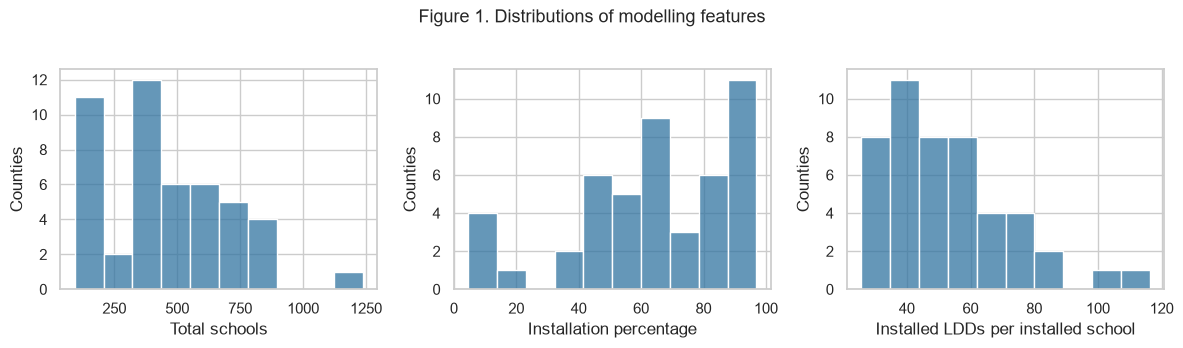

Feature scales differ substantially, so the three features are standardized to mean 0 and standard deviation 1 before anomaly detection and clustering. Tables and substantive interpretations remain in original units.

In [5]:
zero_denominators = county_data["installed_schools"].eq(0)
print(f"Zero installed-school denominators: {zero_denominators.sum()}")
county_data["installed_ldds_per_installed_school"] = (
    county_data["installed_ldds"] / county_data["installed_schools"]
)
feature_columns = ["total_schools", "installation_pct",
                   "installed_ldds_per_installed_school"]
feature_labels = {
    "total_schools": "Total schools",
    "installation_pct": "Installation percentage",
    "installed_ldds_per_installed_school": "Installed LDDs per installed school",
}
features = county_data[feature_columns].copy()
assert np.isfinite(features.to_numpy(dtype=float)).all()
display(features.describe().T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for axis, feature in zip(axes, feature_columns):
    sns.histplot(data=county_data, x=feature, bins=10, color="#3274A1", edgecolor="white", ax=axis)
    axis.set_xlabel(feature_labels[feature])
    axis.set_ylabel("Counties")
fig.suptitle("Figure 1. Distributions of modelling features", y=1.02, fontsize=13)
fig.tight_layout()
plt.show()

scaler = StandardScaler()
standardized_features = scaler.fit_transform(features)
assert np.isfinite(standardized_features).all()
display(Markdown(
    "Feature scales differ substantially, so the three features are standardized to mean 0 and standard deviation 1 "
    "before anomaly detection and clustering. Tables and substantive interpretations remain in original units."
))